In [6]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    classification_report
)

RANDOM_STATE = 737
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)

In [8]:
adult = fetch_ucirepo(id=2)

X_original = adult.data.features.copy()
y_original = adult.data.targets.copy()

df = pd.concat([X_original, y_original], axis=1)

# Standardize column names and text values
df.columns = [
    str(c).strip().lower().replace("-", "_")
    for c in df.columns
]

for col in df.select_dtypes(include=["object", "str"]).columns:
    df[col] = df[col].str.strip()

In [9]:
# Convert '?' to missing values
df = df.replace("?", np.nan)

# Standardize the target labels
df["income"] = (
    df["income"]
    .astype("string")
    .str.replace(r"\.$", "", regex=True)
    .str.strip()
)


In [10]:
# Encode target: 1 = income > $50K; 0 = income <= $50K
df = df.dropna(subset=["income"]).copy()
df["income_binary"] = (df["income"] == ">50K").astype(int)

# Keep a report of duplicate rows; do not automatically remove them
duplicate_count = int(df.duplicated().sum())

# Exclude original income and binary target from features
X = df.drop(columns=["income", "income_binary"])
y = df["income_binary"]

# Demographic variables retained for fairness analysis
sensitive_columns = ["sex", "race"]

In [11]:
# Train/test split: 70% / 30%, required seed 737
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    c for c in X_train.columns
    if c not in numeric_features
]

In [12]:
# Preprocessing:
# Numeric missing values -> median; then standardize.
# Categorical missing values -> most frequent; then one-hot encode.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("DATASET AND PREPROCESSING")
print("=" * 60)
print("Rows:", len(df))
print("Feature count:", X.shape[1])
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Duplicate rows identified:", duplicate_count)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nIncome distribution:")
print(df["income"].value_counts())
print("\nMissing values before imputation:")
print(df[X.columns].isna().sum().sort_values(ascending=False))

# Save original cleaned data for reproducibility
df.to_csv(OUTPUT_DIR / "adult_income_cleaned.csv", index=False)

preprocessing_notes = pd.DataFrame({
    "Decision": [
        "Missing values",
        "Categorical encoding",
        "Feature scaling",
        "Outliers",
        "Duplicates",
        "Train/test split",
        "Target encoding"
    ],
    "Method": [
        "Numeric median; categorical most-frequent imputation, fitted on training data",
        "One-hot encoding with unknown categories ignored",
        "StandardScaler on numeric features, fitted on training data",
        "Retained; inspected with descriptive statistics, not automatically deleted",
        f"{duplicate_count} duplicate rows identified; retained pending investigation",
        "70% train / 30% test, stratified, random_state=737",
        "Income >50K = 1; income <=50K = 0"
    ]
})
preprocessing_notes.to_csv(
    OUTPUT_DIR / "preprocessing_notes.csv", index=False
)
display(preprocessing_notes)

DATASET AND PREPROCESSING
Rows: 48842
Feature count: 14
Training rows: 34189
Testing rows: 14653
Duplicate rows identified: 52
Numeric features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Income distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: Int64

Missing values before imputation:
occupation        2809
workclass         2799
native_country     857
education            0
fnlwgt               0
age                  0
marital_status       0
education_num        0
race                 0
relationship         0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
dtype: int64


,Decision,Method
0,Missing values,Numeric median; categorical most-frequent impu...
1,Categorical encoding,One-hot encoding with unknown categories ignored
2,Feature scaling,"StandardScaler on numeric features, fitted on ..."
3,Outliers,Retained; inspected with descriptive statistic...
4,Duplicates,52 duplicate rows identified; retained pending...
5,Train/test split,"70% train / 30% test, stratified, random_state..."
6,Target encoding,Income >50K = 1; income <=50K = 0


PART 1 — MODEL COMPARISON
OLS median threshold: 0.21791972542604662
Logistic threshold: 0.50
Test cases: 14653
Mismatches: 4631
Mismatch percentage: 31.60%

Agreement/disagreement matrix:


,Logistic predicts 0,Logistic predicts 1
OLS predicts 0,7310,16
OLS predicts 1,4615,2712


,Metric,Value
0,Accuracy,0.849451
1,Precision,0.738270
2,Recall,0.574444
3,F1 score,0.646134
4,ROC-AUC,0.902844


              precision    recall  f1-score   support

           0       0.87      0.94      0.90     11147
           1       0.74      0.57      0.65      3506

    accuracy                           0.85     14653
   macro avg       0.81      0.76      0.78     14653
weighted avg       0.84      0.85      0.84     14653



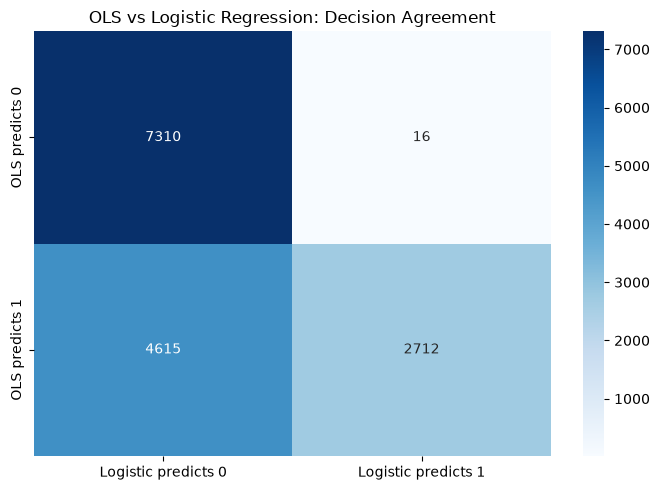

In [13]:
# ============================================================
# PART 1: BUILD BOTH MODELS
# ============================================================

# Model A: Linear regression predicting binary income target
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Model B: Logistic regression predicting income probability
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

ols_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)

# Predictions on the same test set
ols_predictions_continuous = ols_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Required thresholds:
# OLS: median of its test-set predicted values
ols_threshold = float(np.median(ols_predictions_continuous))
ols_binary_predictions = (
    ols_predictions_continuous >= ols_threshold
).astype(int)

# Logistic: probability threshold of 0.5
logistic_binary_predictions = (
    logistic_probabilities >= 0.5
).astype(int)

# Compare the two model decisions
comparison_matrix = confusion_matrix(
    ols_binary_predictions,
    logistic_binary_predictions,
    labels=[0, 1]
)

mismatch_mask = (
    ols_binary_predictions != logistic_binary_predictions
)
mismatch_count = int(mismatch_mask.sum())
mismatch_percentage = 100 * mismatch_count / len(y_test)

comparison_table = pd.DataFrame(
    comparison_matrix,
    index=["OLS predicts 0", "OLS predicts 1"],
    columns=["Logistic predicts 0", "Logistic predicts 1"]
)

print("PART 1 — MODEL COMPARISON")
print("=" * 60)
print("OLS median threshold:", ols_threshold)
print("Logistic threshold: 0.50")
print("Test cases:", len(y_test))
print("Mismatches:", mismatch_count)
print(f"Mismatch percentage: {mismatch_percentage:.2f}%")
print("\nAgreement/disagreement matrix:")
display(comparison_table)

# Actual-target performance for logistic regression
performance = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1 score", "ROC-AUC"
    ],
    "Value": [
        accuracy_score(y_test, logistic_binary_predictions),
        precision_score(
            y_test, logistic_binary_predictions, zero_division=0
        ),
        recall_score(
            y_test, logistic_binary_predictions, zero_division=0
        ),
        f1_score(
            y_test, logistic_binary_predictions, zero_division=0
        ),
        roc_auc_score(y_test, logistic_probabilities)
    ]
})

display(performance)
performance.to_csv(OUTPUT_DIR / "model_performance.csv", index=False)

print(classification_report(
    y_test, logistic_binary_predictions, zero_division=0
))

# Save individual test predictions
test_predictions = X_test.copy()
test_predictions["actual_income"] = y_test
test_predictions["ols_prediction"] = ols_predictions_continuous
test_predictions["ols_class"] = ols_binary_predictions
test_predictions["logistic_probability"] = logistic_probabilities
test_predictions["logistic_class"] = logistic_binary_predictions
test_predictions["model_disagreement"] = mismatch_mask

test_predictions.to_csv(
    OUTPUT_DIR / "test_predictions.csv", index=False
)

# Plot model agreement
plt.figure(figsize=(7, 5))
sns.heatmap(
    comparison_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("OLS vs Logistic Regression: Decision Agreement")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "part1_confusion_matrix.png", dpi=200)
plt.show()

,Group,Education coefficient,CI lower,CI upper,p-value,Training observations
0,Full training data,0.854364,0.820596,0.888132,0.000000e+00,34189
1,Male,0.868841,0.830835,0.906846,0.000000e+00,22902
2,Female,0.988116,0.904980,1.071251,4.935237e-120,11287


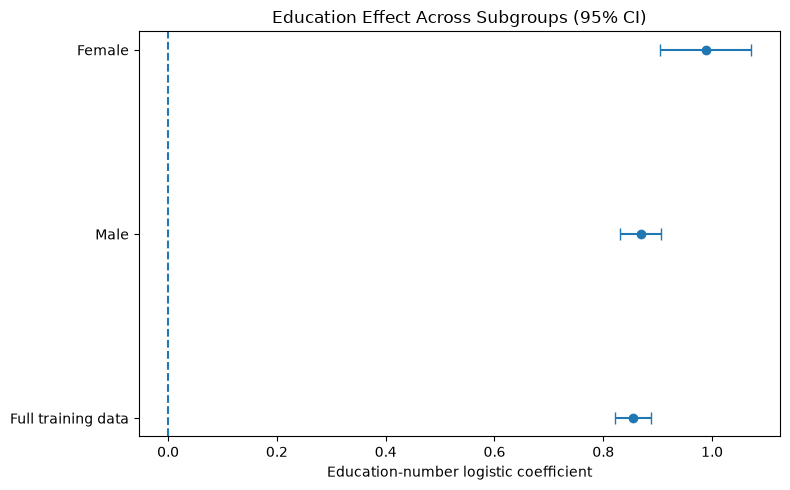

Compare the signs, magnitudes, confidence intervals and p-values. If the signs do not reverse, report meaningful differences in effect size and uncertainty rather than claiming Simpson's paradox.


In [14]:
# ============================================================
# PART 2.1: SUBGROUP ANALYSIS
# ============================================================

# Use numeric predictors for a compact, interpretable comparison
numeric_stress_features = [
    "age", "education_num", "hours_per_week",
    "capital_gain", "capital_loss"
]

def make_stress_data(X_part, y_part):
    temp = X_part[numeric_stress_features].copy()
    temp["sex"] = X_part["sex"].values
    temp["income_binary"] = np.asarray(y_part)
    temp = temp.replace([np.inf, -np.inf], np.nan)
    temp = temp.dropna()
    return temp

stress_train = make_stress_data(X_train, y_train)

# Scale numeric predictors for numerical stability
for col in numeric_stress_features:
    mean_value = stress_train[col].mean()
    std_value = stress_train[col].std()
    if std_value and np.isfinite(std_value):
        stress_train[col] = (stress_train[col] - mean_value) / std_value
    else:
        stress_train[col] = 0.0

def fit_glm(data, formula):
    return smf.glm(
        formula=formula,
        data=data,
        family=sm.families.Binomial()
    ).fit()

subgroup_formula = (
    "income_binary ~ age + education_num + hours_per_week "
    "+ capital_gain + capital_loss"
)

subgroup_results = {}

subgroup_results["Full training data"] = fit_glm(
    stress_train, subgroup_formula
)

for group in ["Male", "Female"]:
    group_data = stress_train[stress_train["sex"] == group]
    if len(group_data) > 100 and group_data["income_binary"].nunique() == 2:
        subgroup_results[group] = fit_glm(
            group_data, subgroup_formula
        )

subgroup_rows = []

for group, result in subgroup_results.items():
    coefficient = result.params["education_num"]
    ci_low, ci_high = result.conf_int().loc["education_num"]
    subgroup_rows.append({
        "Group": group,
        "Education coefficient": coefficient,
        "CI lower": ci_low,
        "CI upper": ci_high,
        "p-value": result.pvalues["education_num"],
        "Training observations": int(result.nobs)
    })

subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table)
subgroup_table.to_csv(
    OUTPUT_DIR / "subgroup_coefficients.csv", index=False
)

plt.figure(figsize=(8, 5))
plt.errorbar(
    subgroup_table["Education coefficient"],
    subgroup_table["Group"],
    xerr=[
        subgroup_table["Education coefficient"] - subgroup_table["CI lower"],
        subgroup_table["CI upper"] - subgroup_table["Education coefficient"]
    ],
    fmt="o",
    capsize=4
)
plt.axvline(0, linestyle="--")
plt.xlabel("Education-number logistic coefficient")
plt.title("Education Effect Across Subgroups (95% CI)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "part2_1_subgroups.png", dpi=200)
plt.show()

print(
    "Compare the signs, magnitudes, confidence intervals and p-values. "
    "If the signs do not reverse, report meaningful differences in "
    "effect size and uncertainty rather than claiming Simpson's paradox."
)

In [15]:
# ============================================================
# PART 2.2: OMITTED-VARIABLE BIAS
# ============================================================

full_formula = (
    "income_binary ~ age + education_num + hours_per_week "
    "+ capital_gain + capital_loss"
)

reduced_formula = (
    "income_binary ~ age + hours_per_week "
    "+ capital_gain + capital_loss"
)

full_ovb_model = fit_glm(stress_train, full_formula)
reduced_ovb_model = fit_glm(stress_train, reduced_formula)

predictors_to_compare = [
    "age", "hours_per_week", "capital_gain", "capital_loss"
]

ovb_rows = []

for predictor in predictors_to_compare:
    before = full_ovb_model.params[predictor]
    after = reduced_ovb_model.params[predictor]

    # Percentage change is undefined when the original coefficient is zero
    pct_change = (
        100 * (after - before) / abs(before)
        if abs(before) > 1e-12 else np.nan
    )

    ovb_rows.append({
        "Predictor": predictor,
        "Full model coefficient": before,
        "Reduced model coefficient": after,
        "Absolute change": abs(after - before),
        "Percentage change": pct_change
    })

ovb_table = pd.DataFrame(ovb_rows)
display(ovb_table)

ovb_table.to_csv(
    OUTPUT_DIR / "omitted_variable_bias.csv", index=False
)

largest_shift = ovb_table.loc[ovb_table["Absolute change"].idxmax()]
print("Largest absolute coefficient shift:", largest_shift["Predictor"])
print("Coefficient change:", largest_shift["Absolute change"])

,Predictor,Full model coefficient,Reduced model coefficient,Absolute change,Percentage change
0,age,0.572760,0.510660,0.062100,-10.842155
1,hours_per_week,0.493096,0.536836,0.043740,8.870400
2,capital_gain,2.491536,2.544521,0.052985,2.126612
3,capital_loss,0.277827,0.312578,0.034751,12.508264


Largest absolute coefficient shift: age
Coefficient change: 0.06209950553223742


In [16]:
# ============================================================
# PART 2.3: ADVERSARIAL SUBSET
# ============================================================

adversarial_mask = (
    ((logistic_probabilities >= 0.75) & (np.asarray(y_test) == 0))
    |
    ((logistic_probabilities <= 0.25) & (np.asarray(y_test) == 1))
)

adversarial = test_predictions.loc[adversarial_mask].copy()

adversarial_count = len(adversarial)
adversarial_percentage = (
    100 * adversarial_count / len(y_test)
)

print("High-confidence incorrect predictions:", adversarial_count)
print(f"Percentage of test set: {adversarial_percentage:.2f}%")

# Required subset size: up to 50 rows, sampled reproducibly if necessary
if adversarial_count > 50:
    adversarial_sample = adversarial.sample(
        n=50, random_state=RANDOM_STATE
    )
else:
    adversarial_sample = adversarial.copy()

print("Rows in reported adversarial sample:", len(adversarial_sample))

demographic_rows = []

for col in ["sex", "race"]:
    if col in X_test.columns:
        full_pct = (
            X_test[col].value_counts(normalize=True, dropna=False) * 100
        )
        subset_pct = (
            adversarial_sample[col].value_counts(
                normalize=True, dropna=False
            ) * 100
        )

        for category in sorted(
            set(full_pct.index).union(set(subset_pct.index)),
            key=str
        ):
            demographic_rows.append({
                "Variable": col,
                "Category": str(category),
                "Full test percentage": full_pct.get(category, 0.0),
                "Adversarial sample percentage": subset_pct.get(
                    category, 0.0
                )
            })

demographic_comparison = pd.DataFrame(demographic_rows)
display(demographic_comparison)

if len(adversarial_sample):
    print("\nAge summary — full test set:")
    display(X_test["age"].describe())

    print("\nAge summary — adversarial sample:")
    display(adversarial_sample["age"].describe())

    print("\nMost common categorical characteristics:")
    for col in ["sex", "race", "education", "marital_status", "occupation"]:
        if col in adversarial_sample.columns:
            print(f"\n{col}:")
            display(
                adversarial_sample[col]
                .value_counts(normalize=True, dropna=False)
                .head(10)
                .mul(100)
                .round(2)
            )

adversarial_sample.to_csv(
    OUTPUT_DIR / "adversarial_subset.csv", index=False
)
demographic_comparison.to_csv(
    OUTPUT_DIR / "adversarial_demographics.csv", index=False
)

High-confidence incorrect predictions: 738
Percentage of test set: 5.04%
Rows in reported adversarial sample: 50


,Variable,Category,Full test percentage,Adversarial sample percentage
0,sex,Female,33.474374,26.0
1,sex,Male,66.525626,74.0
2,race,Amer-Indian-Eskimo,1.160172,0.0
3,race,Asian-Pac-Islander,3.330376,2.0
4,race,Black,9.895585,18.0
5,race,Other,0.777998,2.0
6,race,White,84.835870,78.0



Age summary — full test set:


count    14653.000000
mean        38.691872
std         13.878258
min         17.000000
25%         27.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64


Age summary — adversarial sample:


...

education
HS-grad         40.0
Bachelors       14.0
Some-college    14.0
Masters         12.0
11th             6.0
10th             6.0
Assoc-voc        4.0
Assoc-acdm       2.0
5th-6th          2.0
Name: proportion, dtype: float64


marital_status:


marital_status
Married-civ-spouse    64.0
Never-married         18.0
Divorced              16.0
Married-AF-spouse      2.0
Name: proportion, dtype: float64


occupation:


occupation
Craft-repair         28.0
Prof-specialty       16.0
Other-service        14.0
Exec-managerial      12.0
Sales                 8.0
Transport-moving      6.0
Protective-serv       4.0
Adm-clerical          4.0
Machine-op-inspct     2.0
Priv-house-serv       2.0
Name: proportion, dtype: float64

,Threshold,DP ratio (Female/Male),EO ratio,PP ratio (Female/Male),Female selection rate,Male selection rate,Female TPR,Male TPR,Female FPR,Male FPR,Female PPV,Male PPV
0,0.05,0.464257,0.442709,0.684394,0.333333,0.717993,0.907514,0.986274,0.265390,0.599468,0.288073,0.420917
1,0.15,0.302315,0.246752,0.948870,0.171254,0.566475,0.776493,0.934717,0.099635,0.403786,0.479762,0.505614
2,0.25,0.290495,0.234058,0.971608,0.132314,0.455478,0.701349,0.858052,0.064979,0.277622,0.560863,0.577252
3,0.35,0.292734,0.227101,0.999900,0.103364,0.353098,0.631985,0.745564,0.040812,0.179707,0.646943,0.647008
4,0.45,0.290222,0.232494,0.986444,0.080326,0.276775,0.529865,0.639103,0.027132,0.116699,0.697970,0.707561
5,0.55,0.275626,0.221532,0.988588,0.059123,0.214506,0.420039,0.532307,0.016416,0.074101,0.751724,0.760402
6,0.65,0.280202,0.196674,1.022201,0.044037,0.157160,0.344894,0.415802,0.008436,0.042893,0.828704,0.810705
7,0.75,0.291654,0.184545,1.028404,0.031804,0.109048,0.267823,0.308336,0.003876,0.021003,0.891026,0.866416
8,0.85,0.290833,0.205533,1.006547,0.019572,0.067296,0.173410,0.204553,0.001368,0.006656,0.937500,0.931402
9,0.95,0.333175,0.420408,0.979043,0.011621,0.034879,0.104046,0.110144,0.000684,0.001627,0.947368,0.967647


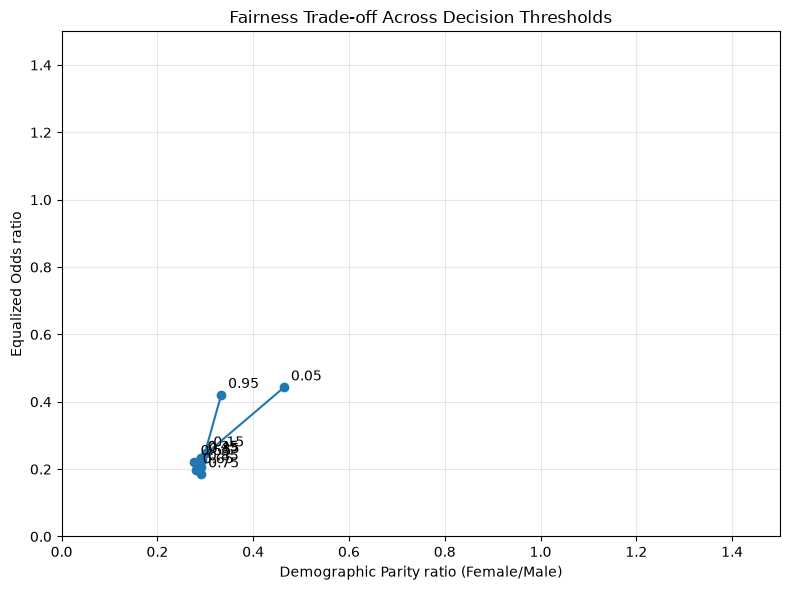

Thresholds with best combined DP/EO proximity:


,Threshold,DP ratio (Female/Male),EO ratio,PP ratio (Female/Male),Female selection rate,Male selection rate,Female TPR,Male TPR,Female FPR,Male FPR,Female PPV,Male PPV,distance_to_DP_EO_ideal
0,0.05,0.464257,0.442709,0.684394,0.333333,0.717993,0.907514,0.986274,0.265390,0.599468,0.288073,0.420917,0.773042
9,0.95,0.333175,0.420408,0.979043,0.011621,0.034879,0.104046,0.110144,0.000684,0.001627,0.947368,0.967647,0.883506
1,0.15,0.302315,0.246752,0.948870,0.171254,0.566475,0.776493,0.934717,0.099635,0.403786,0.479762,0.505614,1.026717


In [17]:
# ============================================================
# PART 2.4: FAIRNESS TRADE-OFF ANALYSIS
# ============================================================

fairness_data = X_test[["sex"]].copy()
fairness_data["actual"] = np.asarray(y_test)
fairness_data["probability"] = logistic_probabilities

fairness_data = fairness_data[
    fairness_data["sex"].isin(["Female", "Male"])
].copy()

def safe_ratio(a, b):
    if b == 0:
        return np.nan
    return a / b

def group_rates(data, group, threshold):
    subset = data[data["sex"] == group]
    actual = subset["actual"].to_numpy()
    pred = (subset["probability"].to_numpy() >= threshold).astype(int)

    positive_rate = pred.mean() if len(pred) else np.nan

    positive_actual = actual == 1
    negative_actual = actual == 0

    tpr = (
        pred[positive_actual].mean()
        if positive_actual.sum() else np.nan
    )
    fpr = (
        pred[negative_actual].mean()
        if negative_actual.sum() else np.nan
    )

    predicted_positive = pred == 1
    ppv = (
        actual[predicted_positive].mean()
        if predicted_positive.sum() else np.nan
    )

    return {
        "n": len(subset),
        "positive_rate": positive_rate,
        "TPR": tpr,
        "FPR": fpr,
        "PPV": ppv
    }

fairness_rows = []

thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)

for threshold in thresholds:
    female = group_rates(fairness_data, "Female", threshold)
    male = group_rates(fairness_data, "Male", threshold)

    dp = safe_ratio(
        female["positive_rate"], male["positive_rate"]
    )

    tpr_ratio = safe_ratio(female["TPR"], male["TPR"])
    fpr_ratio = safe_ratio(female["FPR"], male["FPR"])

    # EO ratio as specified in the assignment:
    # min(TPR_A / TPR_B, FPR_A / FPR_B)
    eo = (
        min(tpr_ratio, fpr_ratio)
        if pd.notna(tpr_ratio) and pd.notna(fpr_ratio)
        else np.nan
    )

    pp = safe_ratio(female["PPV"], male["PPV"])

    fairness_rows.append({
        "Threshold": threshold,
        "DP ratio (Female/Male)": dp,
        "EO ratio": eo,
        "PP ratio (Female/Male)": pp,
        "Female selection rate": female["positive_rate"],
        "Male selection rate": male["positive_rate"],
        "Female TPR": female["TPR"],
        "Male TPR": male["TPR"],
        "Female FPR": female["FPR"],
        "Male FPR": male["FPR"],
        "Female PPV": female["PPV"],
        "Male PPV": male["PPV"]
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table)

fairness_table.to_csv(
    OUTPUT_DIR / "fairness_metrics_by_threshold.csv", index=False
)

# Trade-off chart: DP vs EO
plt.figure(figsize=(8, 6))
valid = fairness_table.dropna(
    subset=["DP ratio (Female/Male)", "EO ratio"]
)

plt.plot(
    valid["DP ratio (Female/Male)"],
    valid["EO ratio"],
    marker="o"
)

for _, row in valid.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (
            row["DP ratio (Female/Male)"],
            row["EO ratio"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Female/Male)")
plt.ylabel("Equalized Odds ratio")
plt.title("Fairness Trade-off Across Decision Thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "part2_4_fairness_tradeoff.png", dpi=200)
plt.show()

# Show the threshold closest to DP=1 and EO=1, without using PP to choose it
fairness_table["distance_to_DP_EO_ideal"] = np.sqrt(
    (fairness_table["DP ratio (Female/Male)"] - 1) ** 2
    + (fairness_table["EO ratio"] - 1) ** 2
)

print("Thresholds with best combined DP/EO proximity:")
display(
    fairness_table.sort_values("distance_to_DP_EO_ideal").head(3)
)

In [18]:
# ============================================================
# EXPORT RESULTS FOR REPORT
# ============================================================

summary = {
    "Dataset": "Adult Census Income (UCI ID 2)",
    "Random state": RANDOM_STATE,
    "Total rows after target cleaning": len(df),
    "Training rows": len(X_train),
    "Test rows": len(X_test),
    "Features": X.shape[1],
    "Duplicate rows identified": duplicate_count,
    "OLS threshold": ols_threshold,
    "Model disagreement count": mismatch_count,
    "Model disagreement percentage": mismatch_percentage,
    "Adversarial count": adversarial_count,
    "Adversarial percentage of test set": adversarial_percentage,
    "Logistic accuracy": accuracy_score(
        y_test, logistic_binary_predictions
    ),
    "Logistic precision": precision_score(
        y_test, logistic_binary_predictions, zero_division=0
    ),
    "Logistic recall": recall_score(
        y_test, logistic_binary_predictions, zero_division=0
    ),
    "Logistic F1": f1_score(
        y_test, logistic_binary_predictions, zero_division=0
    ),
    "Logistic ROC-AUC": roc_auc_score(
        y_test, logistic_probabilities
    )
}

summary_df = pd.DataFrame(
    list(summary.items()), columns=["Metric", "Value"]
)

summary_df.to_csv(OUTPUT_DIR / "assignment_summary.csv", index=False)
display(summary_df)

# Export all notebook tables as CSVs.
print("\nFiles saved in:", OUTPUT_DIR.resolve())
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)

,Metric,Value
0,Dataset,Adult Census Income (UCI ID 2)
1,Random state,737
2,Total rows after target cleaning,48842
3,Training rows,34189
4,Test rows,14653
5,Features,14
6,Duplicate rows identified,52
7,OLS threshold,0.21792
8,Model disagreement count,4631
9,Model disagreement percentage,31.60445



Files saved in: C:\Users\HP\OneDrive\Documents\CSET485 Assignment\.venv\results
adult_income_cleaned.csv
adversarial_demographics.csv
adversarial_subset.csv
assignment_summary.csv
fairness_metrics_by_threshold.csv
model_performance.csv
omitted_variable_bias.csv
part1_confusion_matrix.png
part2_1_subgroups.png
part2_4_fairness_tradeoff.png
preprocessing_notes.csv
subgroup_coefficients.csv
test_predictions.csv


In [19]:
# ============================================================
# NUMERICAL EVIDENCE FOR PART 3 AND PART 4
# ============================================================

evidence = []

evidence.append(("Test set size", len(y_test)))
evidence.append(("OLS median threshold", ols_threshold))
evidence.append(("Model disagreement count", mismatch_count))
evidence.append(("Model disagreement percentage", mismatch_percentage))
evidence.append(("Logistic accuracy", accuracy_score(
    y_test, logistic_binary_predictions
)))
evidence.append(("Logistic ROC-AUC", roc_auc_score(
    y_test, logistic_probabilities
)))
evidence.append(("High-confidence wrong predictions", adversarial_count))
evidence.append(("High-confidence wrong prediction percentage", adversarial_percentage))

if "education_num" in subgroup_table.columns or (
    "Education coefficient" in subgroup_table.columns
):
    evidence.append((
        "Subgroup coefficient table",
        "See subgroup_coefficients.csv"
    ))

if not ovb_table.empty:
    evidence.append((
        "Largest omitted-variable coefficient shift",
        str(largest_shift["Predictor"])
    ))
    evidence.append((
        "Largest omitted-variable absolute change",
        largest_shift["Absolute change"]
    ))

evidence.append((
    "Fairness table",
    "See fairness_metrics_by_threshold.csv"
))
evidence.append((
    "Fairness trade-off graph",
    "See part2_4_fairness_tradeoff.png"
))

evidence_df = pd.DataFrame(evidence, columns=["Evidence item", "Computed value"])
evidence_df.to_csv(OUTPUT_DIR / "written_answer_evidence.csv", index=False)
display(evidence_df)

,Evidence item,Computed value
0,Test set size,14653
1,OLS median threshold,0.21792
2,Model disagreement count,4631
3,Model disagreement percentage,31.60445
4,Logistic accuracy,0.849451
5,Logistic ROC-AUC,0.902844
6,High-confidence wrong predictions,738
7,High-confidence wrong prediction percentage,5.036511
8,Subgroup coefficient table,See subgroup_coefficients.csv
9,Largest omitted-variable coefficient shift,age
